In [57]:
import sys

print("Python Version:", sys.version)
print("Python Path:", sys.executable)

try:
    import pyspark
    print("PySpark Version:", pyspark.__version__)
except ImportError:
    print("PySpark is not available in this notebook environment.")
    

Python Version: 3.12.8 | packaged by Anaconda, Inc. | (main, Dec 11 2024, 16:48:34) [MSC v.1929 64 bit (AMD64)]
Python Path: C:\Users\jaisw\anaconda3\python.exe
PySpark Version: 3.5.9


In [4]:
%pip install pyspark==3.5.9

Note: you may need to restart the kernel to use updated packages.


In [59]:
import pyspark
print("PySpark Version:", pyspark.__version__)

PySpark Version: 3.5.9


In [61]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("HousePricePrediction") \
    .master("local[*]") \
    .getOrCreate()

print("Spark Version:", spark.version)

spark.range(5).show() 

Spark Version: 3.5.9
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



In [5]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("CSV found:", Path("Housing.csv").exists())

Current folder: C:\Users\jaisw
CSV found: True


In [63]:

# Step 1: Load the housing dataset in Spark

df = spark.read.csv(
    "Housing.csv",
    header=True,
    inferSchema=True
)

print("Total rows:", df.count())
print("Total columns:", len(df.columns))

df.show(5)


Total rows: 545
Total columns: 13
+--------+----+--------+---------+-------+--------+---------+--------+---------------+---------------+-------+--------+----------------+
|   price|area|bedrooms|bathrooms|stories|mainroad|guestroom|basement|hotwaterheating|airconditioning|parking|prefarea|furnishingstatus|
+--------+----+--------+---------+-------+--------+---------+--------+---------------+---------------+-------+--------+----------------+
|13300000|7420|       4|        2|      3|     yes|       no|      no|             no|            yes|      2|     yes|       furnished|
|12250000|8960|       4|        4|      4|     yes|       no|      no|             no|            yes|      3|      no|       furnished|
|12250000|9960|       3|        2|      2|     yes|       no|     yes|             no|             no|      2|     yes|  semi-furnished|
|12215000|7500|       4|        2|      2|     yes|       no|     yes|             no|            yes|      3|     yes|       furnished|
|114100

In [9]:

from pyspark.sql import functions as F

# Check missing values
df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df.columns
]).show(truncate=False)

# Check duplicate rows
print("Total rows:", df.count())
print("Unique rows:", df.dropDuplicates().count())
print("Duplicate rows:", df.count() - df.dropDuplicates().count())


+-----+----+--------+---------+-------+--------+---------+--------+---------------+---------------+-------+--------+----------------+
|price|area|bedrooms|bathrooms|stories|mainroad|guestroom|basement|hotwaterheating|airconditioning|parking|prefarea|furnishingstatus|
+-----+----+--------+---------+-------+--------+---------+--------+---------------+---------------+-------+--------+----------------+
|0    |0   |0       |0        |0      |0       |0        |0       |0              |0              |0      |0       |0               |
+-----+----+--------+---------+-------+--------+---------+--------+---------------+---------------+-------+--------+----------------+

Total rows: 545
Unique rows: 545
Duplicate rows: 0


In [65]:
categorical_cols = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea",
    "furnishingstatus"
]

indexed_df = df

for col_name in categorical_cols:
    index_col = col_name + "_index"

    if index_col in indexed_df.columns:
        indexed_df = indexed_df.drop(index_col)

print("Existing index columns cleared.")

Existing index columns cleared.


In [19]:
from pyspark.ml.feature import StringIndexer

for col_name in categorical_cols:
    indexer = StringIndexer(
        inputCol=col_name,
        outputCol=col_name + "_index"
    )

    indexer_model = indexer.fit(indexed_df)
    indexed_df = indexer_model.transform(indexed_df)

indexed_df.select(
    categorical_cols + [c + "_index" for c in categorical_cols]
).show(5, truncate=False)

+--------+---------+--------+---------------+---------------+--------+----------------+--------------+---------------+--------------+---------------------+---------------------+--------------+----------------------+
|mainroad|guestroom|basement|hotwaterheating|airconditioning|prefarea|furnishingstatus|mainroad_index|guestroom_index|basement_index|hotwaterheating_index|airconditioning_index|prefarea_index|furnishingstatus_index|
+--------+---------+--------+---------------+---------------+--------+----------------+--------------+---------------+--------------+---------------------+---------------------+--------------+----------------------+
|yes     |no       |no      |no             |yes            |yes     |furnished       |0.0           |0.0            |0.0           |0.0                  |1.0                  |1.0           |2.0                   |
|yes     |no       |no      |no             |yes            |no      |furnished       |0.0           |0.0            |0.0           |0.0

In [21]:
from pyspark.ml.feature import VectorAssembler

# Select input features
feature_cols = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "mainroad_index",
    "guestroom_index",
    "basement_index",
    "hotwaterheating_index",
    "airconditioning_index",
    "parking",
    "prefarea_index",
    "furnishingstatus_index"
]

# Combine all features into one vector
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

data = assembler.transform(indexed_df)

# Display the result
data.select("features", "price").show(5, truncate=False)

+----------------------------------------------------+--------+
|features                                            |price   |
+----------------------------------------------------+--------+
|[7420.0,4.0,2.0,3.0,0.0,0.0,0.0,0.0,1.0,2.0,1.0,2.0]|13300000|
|[8960.0,4.0,4.0,4.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,2.0]|12250000|
|[9960.0,3.0,2.0,2.0,0.0,0.0,1.0,0.0,0.0,2.0,1.0,0.0]|12250000|
|[7500.0,4.0,2.0,2.0,0.0,0.0,1.0,0.0,1.0,3.0,1.0,2.0]|12215000|
|[7420.0,4.0,1.0,2.0,0.0,1.0,1.0,0.0,1.0,2.0,0.0,2.0]|11410000|
+----------------------------------------------------+--------+
only showing top 5 rows



In [23]:
# Split data into training and testing sets
train_data, test_data = data.randomSplit(
    [0.7, 0.3],
    seed=42
)
print("Training rows:", train_data.count())
print("Testing rows:", test_data.count())

Training rows: 408
Testing rows: 137


In [25]:
from pyspark.ml.regression import LinearRegression
lr = LinearRegression(
    featuresCol="features",
    labelCol="price"
)

# Train the model
lr_model = lr.fit(train_data)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [27]:
# Make predictions on test data
predictions = lr_model.transform(test_data)

# Display actual price and predicted price
predictions.select(
    "price",
    "prediction"
).show(10, truncate=False)

+-------+------------------+
|price  |prediction        |
+-------+------------------+
|1750000|3433822.9704747936|
|1890000|2939268.1390660666|
|1960000|3262731.852583478 |
|2100000|3100285.9911526293|
|2233000|4543701.121602951 |
|2240000|3057693.254002328 |
|2275000|2349301.4056449514|
|2345000|2788909.122359706 |
|2380000|4396419.162771732 |
|2408000|2389003.3888431126|
+-------+------------------+
only showing top 10 rows



In [29]:
from pyspark.ml.evaluation import RegressionEvaluator

# Calculate RMSE
evaluator = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="rmse"
)

rmse = evaluator.evaluate(predictions)

print("RMSE:", rmse)

RMSE: 1028580.4123453875


In [31]:
from pyspark.ml.evaluation import RegressionEvaluator

evaluator_mae = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="mae"
)

mae = evaluator_mae.evaluate(predictions)

print("MAE:", mae)

MAE: 790887.255582006


In [33]:
evaluator_r2 = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="r2"
)

r2 = evaluator_r2.evaluate(predictions)

print("R²:", r2)

R²: 0.662067349370648


In [35]:
from pyspark.ml.regression import DecisionTreeRegressor

dt = DecisionTreeRegressor(
    featuresCol="features",
    labelCol="price"
)

dt_model = dt.fit(train_data)

print("Decision Tree Regression model trained successfully!")

Decision Tree Regression model trained successfully!


In [37]:
dt_predictions = dt_model.transform(test_data)

dt_predictions.select(
    "price",
    "prediction"
).show(10, truncate=False)

+-------+------------------+
|price  |prediction        |
+-------+------------------+
|1750000|3420750.0         |
|1890000|3420750.0         |
|1960000|3420750.0         |
|2100000|3420750.0         |
|2233000|4668382.352941177 |
|2240000|3420750.0         |
|2275000|3561097.8260869565|
|2345000|2722461.5384615385|
|2380000|4542160.0         |
|2408000|2722461.5384615385|
+-------+------------------+
only showing top 10 rows



In [39]:
from pyspark.ml.evaluation import RegressionEvaluator

dt_rmse = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="rmse"
).evaluate(dt_predictions)

dt_mae = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="mae"
).evaluate(dt_predictions)

dt_r2 = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="r2"
).evaluate(dt_predictions)

print("Decision Tree R²:", dt_r2)
print("Decision Tree RMSE:", dt_rmse)
print("Decision Tree MAE:", dt_mae)

Decision Tree R²: 0.34217234391167484
Decision Tree RMSE: 1435090.3238430722
Decision Tree MAE: 1037644.6415146317


In [49]:
import pandas as pd

comparison_df = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "R2": 0.662067349370648,
        "RMSE": 1028580.4123453875,
        "MAE": 790887.255582006
    },
    {
        "Model": "Decision Tree",
        "R2": 0.34217234391167484,
        "RMSE": 1435090.3238430722,
        "MAE": 1037644.6415146317
    }
])

comparison_df


,Model,R2,RMSE,MAE
0,Linear Regression,0.662067,1.028580e+06,7.908873e+05
1,Decision Tree,0.342172,1.435090e+06,1.037645e+06


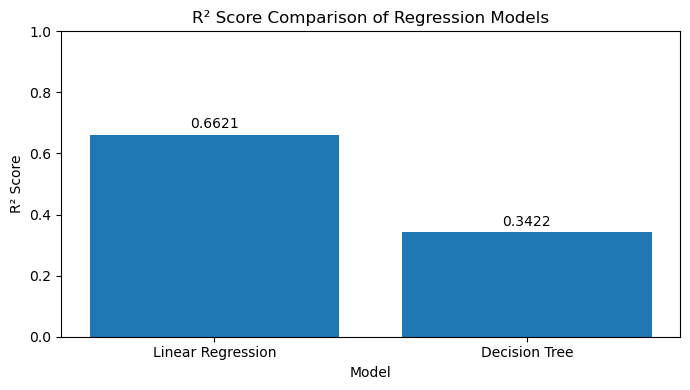

In [51]:

import matplotlib.pyplot as plt

models = ["Linear Regression", "Decision Tree"]
r2_scores = [0.6621, 0.3422]

plt.figure(figsize=(7, 4))
plt.bar(models, r2_scores)
plt.title("R² Score Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)

for i, score in enumerate(r2_scores):
    plt.text(i, score + 0.02, f"{score:.4f}", ha="center")

plt.tight_layout()
plt.show()


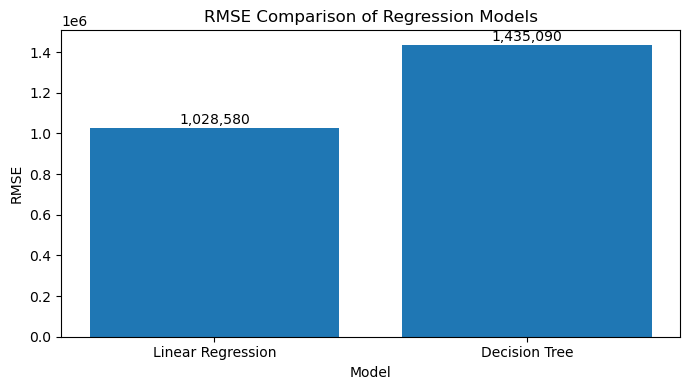

In [53]:

import matplotlib.pyplot as plt

models = ["Linear Regression", "Decision Tree"]
rmse_scores = [1028580.41, 1435090.32]

plt.figure(figsize=(7, 4))
plt.bar(models, rmse_scores)

plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("RMSE")

for i, score in enumerate(rmse_scores):
    plt.text(i, score + 20000, f"{score:,.0f}", ha="center")

plt.tight_layout()
plt.show()


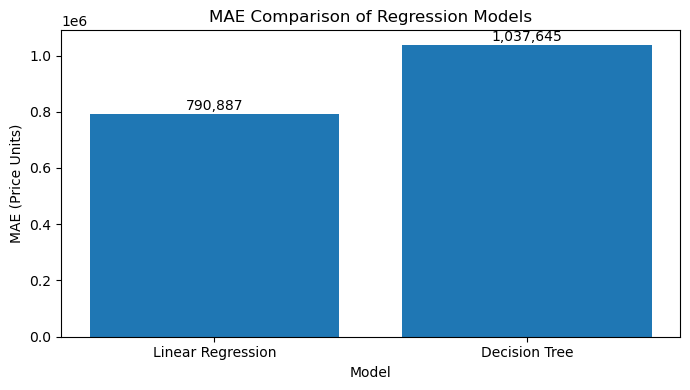

In [67]:

import matplotlib.pyplot as plt

models = ["Linear Regression", "Decision Tree"]
mae_scores = [790887.26, 1037644.64]

plt.figure(figsize=(7, 4))
plt.bar(models, mae_scores)

plt.title("MAE Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("MAE (Price Units)")

for i, score in enumerate(mae_scores):
    plt.text(i, score + 15000, f"{score:,.0f}", ha="center")

plt.tight_layout()
plt.show()
